<a href="https://colab.research.google.com/github/ixrlts/data-analytics-case-studies/blob/main/projects/taxis/01_taxi_rides_by_hour.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('taxis')
df.head(10)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
5,2019-03-11 10:37:23,2019-03-11 10:47:31,1,0.49,7.5,2.16,0.0,12.96,yellow,credit card,Times Sq/Theatre District,Midtown East,Manhattan,Manhattan
6,2019-03-26 21:07:31,2019-03-26 21:17:29,1,3.65,13.0,2.00,0.0,18.80,yellow,credit card,Battery Park City,Two Bridges/Seward Park,Manhattan,Manhattan
7,2019-03-22 12:47:13,2019-03-22 12:58:17,0,1.40,8.5,0.00,0.0,11.80,yellow,NaN,Murray Hill,Flatiron,Manhattan,Manhattan
8,2019-03-23 11:48:50,2019-03-23 12:06:14,1,3.63,15.0,1.00,0.0,19.30,yellow,credit card,East Harlem South,Midtown Center,Manhattan,Manhattan
9,2019-03-08 16:18:37,2019-03-08 16:26:57,1,1.52,8.0,1.00,0.0,13.30,yellow,credit card,Lincoln Square East,Central Park,Manhattan,Manhattan


In [47]:
df['ride_time'] = df['dropoff'] -  df['pickup']
df['ride_min'] = df['ride_time'].dt.total_seconds() / 60
df[df['ride_min'] > 0]
df['speed_mph'] = df['distance'] / df['ride_min'] * 60
df['hour'] = df['pickup'].dt.hour
by_hour = df.groupby('hour').agg(
    median_min=('ride_min', 'median'),
    median_speed=('speed_mph', 'median'),
    rides=('ride_min', 'size')
)
by_hour


,median_min,median_speed,rides
hour,,,
0,10.733333,12.802432,205
1,9.633333,13.567706,110
2,9.183333,14.472255,101
3,9.583333,14.425532,67
4,10.500000,16.615385,57
5,8.700000,16.951337,51
6,7.833333,14.697248,142
7,9.583333,11.827338,221
8,11.316667,9.313836,313


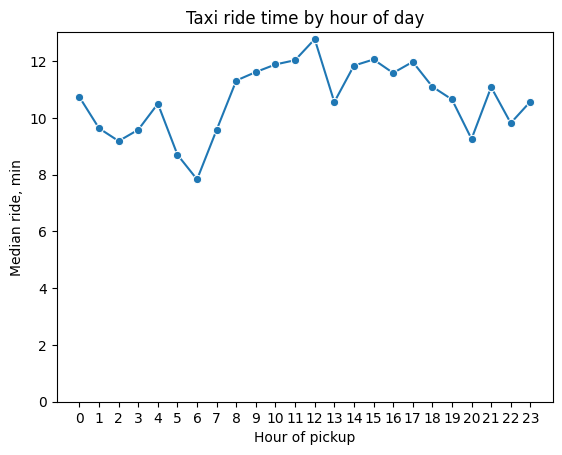

In [54]:
sns.lineplot(data=by_hour, x='hour', y='median_min', marker='o')
plt.title('Taxi ride time by hour of day')
plt.xlabel('Hour of pickup')
plt.ylabel('Median ride, min')
plt.xticks(range(0, 24))
plt.ylim(0)
plt.show()

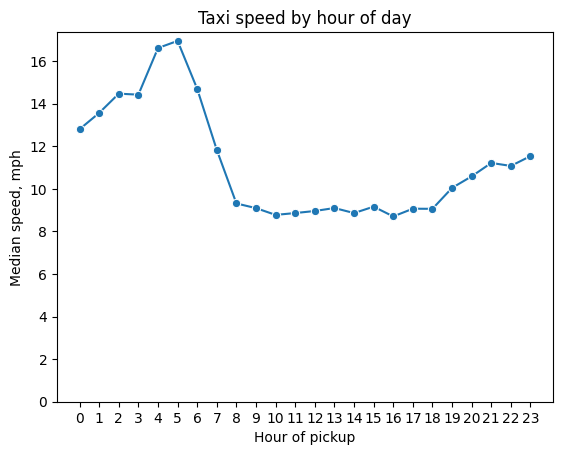

In [56]:
sns.lineplot(data=by_hour, x='hour', y='median_speed', marker='o')
plt.title('Taxi speed by hour of day')
plt.xlabel('Hour of pickup')
plt.ylabel('Median speed, mph')
plt.xticks(range(0, 24))
plt.ylim(0)
plt.show()

Taxi rides are slowest during the day, from 8:00 to 18:00 the median speed is about 9 mph, compared with 13-17 mph at night. As a result, a typical daytime rides are longer and takes 11-12 minutes, as opposed to about 8 minutes early in the morning. Medians were used because a few records are invalid and ride times are right-skewed.